# Case-Based Assessment: Student Depression Analysis
**Name:** Vishonika | **Roll No.:** 26PGDM093
**Course:** Data Analytics for Managers Using Python

**Dataset:** Student Depression Detection Dataset (4,464 students, 13 columns)



In [3]:
!pip install seaborn plotly statsmodels

# Lecture 1 - Load the data and Python basics

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sns.set_style("whitegrid")

# Excel file path
FILE = "/content/26PGDM093_Vishonika_CaseAssessment.xlsx"

# Load the UNCLEANED data (raw) from the Excel file
raw = pd.read_excel(FILE, sheet_name="Raw_Data")

print("Data loaded:", raw.shape[0], "students and", raw.shape[1], "variables")
raw.head()

Data loaded: 4464 students and 13 variables


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


# Variables, data types and operators

In [5]:
# Variables
total_students = raw.shape[0]                     # int
average_cgpa = raw["CGPA"].mean()                 # float
dataset_name = "Student Depression Dataset"       # string
has_missing = raw.isnull().sum().sum() > 0        # bool

print("Total students :", total_students, type(total_students))
print("Average CGPA   :", round(average_cgpa, 2), type(average_cgpa))
print("Dataset name   :", dataset_name, type(dataset_name))
print("Any missing?   :", has_missing, type(has_missing))

# Operators
depressed = (raw["Depression"] == "Yes").sum()
not_depressed = total_students - depressed            # subtraction
rate = depressed / total_students * 100                # division and multiplication

print("\nDepressed students    :", depressed)
print("Not depressed students:", not_depressed)
print("Depression rate (%)   :", round(rate, 1))
print("Is rate above 25%?    :", rate > 25)            # comparison operator

Total students : 4464 <class 'int'>
Average CGPA   : 3.41 <class 'numpy.float64'>
Dataset name   : Student Depression Dataset <class 'str'>
Any missing?   : False <class 'numpy.bool'>

Depressed students    : 1201
Not depressed students: 3263
Depression rate (%)   : 26.9
Is rate above 25%?    : True


# Lecture 2 - Decision making structures

In [6]:
# If Statement
rate = (raw["Depression"] == "Yes").mean() * 100

if rate > 20:
    print("More than 1 in 5 students is depressed - the university must act")

More than 1 in 5 students is depressed - the university must act


In [7]:
# If else
average_cgpa = raw["CGPA"].mean()

if average_cgpa >= 3.5:
    print("Average CGPA is high")
else:
    print("Average CGPA is below 3.5")

Average CGPA is below 3.5


In [8]:
# Nested If Statement
rate = (raw["Depression"] == "Yes").mean() * 100
average_cgpa = raw["CGPA"].mean()

if rate > 20:
    print("Depression rate is high")

    if average_cgpa < 3.5:
        print("Academic performance also needs support")
    else:
        print("Grades are fine, focus on wellbeing")

else:
    print("Depression rate is low")

Depression rate is high
Academic performance also needs support


In [9]:
# If - elif - else : grade band of the average CGPA
cgpa = raw["CGPA"].mean()

if cgpa >= 3.75:
    print("Excellent")
elif cgpa >= 3.25:
    print("Good")
elif cgpa >= 2.75:
    print("Average")
else:
    print("Needs Improvement")

Good


# Lecture 3 - Loops

In [10]:
# For Loop: check the first 10 students
for cgpa in raw["CGPA"].head(10):
    if cgpa >= 3.5:
        print(cgpa, "Good CGPA")
    else:
        print(cgpa, "Needs support")

3.43 Needs support
3.7 Good CGPA
3.28 Needs support
3.77 Good CGPA
4.0 Good CGPA
3.8 Good CGPA
3.5 Good CGPA
2.71 Needs support
3.1 Needs support
3.34 Needs support


In [11]:
# For Loop with range() - iloc = integer location
for i in range(10):
    print(raw["Gender"].iloc[i], raw["CGPA"].iloc[i], raw["Depression"].iloc[i])

Female 3.43 Yes
Male 3.7 Yes
Male 3.28 Yes
Male 3.77 No
Female 4.0 Yes
Female 3.8 No
Female 3.5 No
Female 2.71 Yes
Female 3.1 Yes
Female 3.34 No


In [12]:
# WHILE Loop
i = 0

while i < 5:
    health = raw["Health_condition"].iloc[i]

    if health == "Critical" or health == "Abnormal":
        print("Student", i, "-> health is", health, "-> refer to counsellor")
    else:
        print("Student", i, "-> health is", health, "-> OK")

    i = i + 1

Student 0 -> health is Critical -> refer to counsellor
Student 1 -> health is Abnormal -> refer to counsellor
Student 2 -> health is Abnormal -> refer to counsellor
Student 3 -> health is Good -> OK
Student 4 -> health is Abnormal -> refer to counsellor


# A function we wrote

In [13]:
# Function: returns the depression rate (%) of any group of students
def depression_rate(data):
    rate = (data["Depression"] == "Yes").mean() * 100
    return round(rate, 1)

print("All students       :", depression_rate(raw), "%")
print("No friend circle   :", depression_rate(raw[raw["friend_circle"] == "No"]), "%")
print("Has friend circle  :", depression_rate(raw[raw["friend_circle"] == "Yes"]), "%")

All students       : 26.9 %
No friend circle   : 34.3 %
Has friend circle  : 24.0 %


# Lecture 4 - Data structures: list, tuple, set and dictionary

In [14]:
# LIST: the 8 home divisions
divisions = ["Dhaka", "Chittagong", "Khulna", "Rajshahi", "Sylhet", "Rangpur", "Barisal", "Mymensingh"]

# TUPLE: one student's fixed details (Gender, Age, Division)
student = ("Female", 22, "Chittagong")

# SET: health conditions (duplicate 'Normal' is removed automatically)
health_set = {"Good", "Normal", "Abnormal", "Critical", "Normal"}

# DICTIONARY: health condition -> score
health_score = {
    "Critical": 1,
    "Abnormal": 2,
    "Normal": 3,
    "Good": 4
}

print("List:", divisions)
print("Tuple:", student)
print("Set:", health_set)
print("Dictionary:", health_score)
print()
print("'Normal' typed twice, stored once in set?", len(health_set) == 4)
print(type(divisions), type(student), type(health_set), type(health_score))

List: ['Dhaka', 'Chittagong', 'Khulna', 'Rajshahi', 'Sylhet', 'Rangpur', 'Barisal', 'Mymensingh']
Tuple: ('Female', 22, 'Chittagong')
Set: {'Abnormal', 'Good', 'Normal', 'Critical'}
Dictionary: {'Critical': 1, 'Abnormal': 2, 'Normal': 3, 'Good': 4}

'Normal' typed twice, stored once in set? True
<class 'list'> <class 'tuple'> <class 'set'> <class 'dict'>


# Accessing the elements of the data

In [15]:
# --- List ---
print("First item     :", divisions[0])
print("Last item      :", divisions[-1])
print("First three    :", divisions[0:3])
print("Every 2nd item :", divisions[::2])

# --- Tuple ---
print("\nStudent gender :", student[0])
print("Student division:", student[2])

# --- Dictionary ---
print("\nScore of Good health :", health_score["Good"])
print("Safe lookup          :", health_score.get("Excellent", "Not a category"))

# --- Set ---
print("\nIs Critical a health level?", "Critical" in health_set)
print("Is Perfect a health level? ", "Perfect" in health_set)

First item     : Dhaka
Last item      : Mymensingh
First three    : ['Dhaka', 'Chittagong', 'Khulna']
Every 2nd item : ['Dhaka', 'Khulna', 'Sylhet', 'Barisal']

Student gender : Female
Student division: Chittagong

Score of Good health : 4
Safe lookup          : Not a category

Is Critical a health level? True
Is Perfect a health level?  False


# Apply functions to data structures

In [16]:
# Built-in functions on the CGPA list
cgpa_list = raw["CGPA"].tolist()

print("Number of students :", len(cgpa_list))
print("Average CGPA       :", round(sum(cgpa_list) / len(cgpa_list), 2))
print("Highest CGPA       :", max(cgpa_list))
print("Lowest CGPA        :", min(cgpa_list))
print("Top 5 CGPAs        :", sorted(cgpa_list, reverse=True)[:5])

Number of students : 4464
Average CGPA       : 3.41
Highest CGPA       : 4.0
Lowest CGPA        : 2.25
Top 5 CGPAs        : [4.0, 4.0, 4.0, 4.0, 4.0]


# NumPy array operations

In [17]:
cost = np.array(raw["Cost_without_study"])

print("Average monthly cost (BDT):", round(np.mean(cost), 2))
print("Median monthly cost (BDT) :", np.median(cost))
print("Yearly cost of first 5    :", cost[:5] * 12)        # array maths: every value x 12
print("Students above 20,000 BDT :", np.sum(cost > 20000))

Average monthly cost (BDT): 11242.98
Median monthly cost (BDT) : 9500.0
Yearly cost of first 5    : [121356 165780 185400 208956 200316]
Students above 20,000 BDT : 436


# Pandas Series and DataFrame - indexing and selection

In [18]:
# Series = one column
cgpa_series = raw["CGPA"]
print(type(cgpa_series))

# DataFrame = many columns
small = raw[["Gender", "CGPA", "Depression"]]
print(type(small))

# loc = select by label / condition, iloc = select by position
print(raw.loc[raw["Health_condition"] == "Critical", ["Gender", "CGPA", "Depression"]].head())
print(raw.iloc[0:3, 0:4])

<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>
    Gender  CGPA Depression
0   Female  3.43        Yes
14    Male  3.00        Yes
16    Male  3.28        Yes
17  Female  3.15        Yes
28    Male  3.13        Yes
   Gender  Age Family_background Relationship_status
0  Female   22      Middle class              Single
1    Male   19      Middle class              Single
2    Male   23      Middle class              Single


# Lecture 5 - Descriptive statistics: first look at the data

In [19]:
# 1. shape: number of rows and columns
print("shape:", raw.shape)

# 2. Columns
print("\nColumns")
print(raw.columns)

# 3. Index
print("\nIndex:")
print(raw.index)

# 4. Data Types
print("\nData Types:")
print(raw.dtypes)

# 5. Structure Summary
raw.info()

shape: (4464, 13)

Columns
Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='object')

Index:
RangeIndex(start=0, stop=4464, step=1)

Data Types:
Gender                  object
Age                      int64
Family_background       object
Relationship_status     object
Marital_status          object
Living_style            object
Current_semester         int64
CGPA                   float64
friend_circle           object
Health_condition        object
Cost_without_study       int64
Home_division           object
Depression              object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender              

# Classification of data

In [20]:
number_cols = [
    "Age",
    "Current_semester",
    "CGPA",
    "Cost_without_study"
]

category_cols = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "friend_circle",
    "Health_condition",
    "Home_division",
    "Depression"
]

date_cols = []     # this dataset has no date column

print("Numerical  :", len(number_cols), number_cols)
print("Categorical:", len(category_cols), category_cols)
print("Date       :", len(date_cols), date_cols)

Numerical  : 4 ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
Categorical: 9 ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division', 'Depression']
Date       : 0 []


In [21]:
# Data Quality Check

# 1. Missing values in each column
print("Missing Values:")
print(raw.isnull().sum())

# 2. Duplicate rows
print("\nDuplicate Rows:")
print(raw.duplicated().sum())

Missing Values:
Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

Duplicate Rows:
0


In [22]:
# describe(): many statistics in one command
raw[number_cols].describe().round(2)

,Age,Current_semester,CGPA,Cost_without_study
count,4464.00,4464.00,4464.00,4464.00
mean,22.62,5.40,3.41,11242.98
std,2.02,2.58,0.39,6640.14
min,17.00,0.00,2.25,0.00
25%,21.00,3.00,3.15,6100.00
50%,23.00,5.00,3.49,9500.00
75%,24.00,7.00,3.70,15439.00
max,28.00,13.00,4.00,32000.00


In [23]:
# Statistics for one important column: CGPA
cgpa = raw["CGPA"]

print("Mean (average)     :", round(cgpa.mean(), 2))
print("Median (middle)    :", cgpa.median())
print("Mode (most common) :", cgpa.mode()[0])
print("Minimum            :", cgpa.min())
print("Maximum            :", cgpa.max())
print("Standard deviation :", round(cgpa.std(), 2))
print("Range (max - min)  :", cgpa.max() - cgpa.min())

Mean (average)     : 3.41
Median (middle)    : 3.49
Mode (most common) : 3.0
Minimum            : 2.25
Maximum            : 4.0
Standard deviation : 0.39
Range (max - min)  : 1.75


# Comparison of mean and median

In [24]:
cost = raw["Cost_without_study"]
mean_value = cost.mean()
median_value = cost.median()

print(f"Mean   = BDT {mean_value:,.2f}")
print(f"Median = BDT {median_value:,.2f}")

if mean_value > median_value:
    print("A few high spenders may be pulling the average up.")
else:
    print("The average is close to or below the median.")

Mean   = BDT 11,242.98
Median = BDT 9,500.00
A few high spenders may be pulling the average up.


# Lecture 6 - Data visualization (first charts)

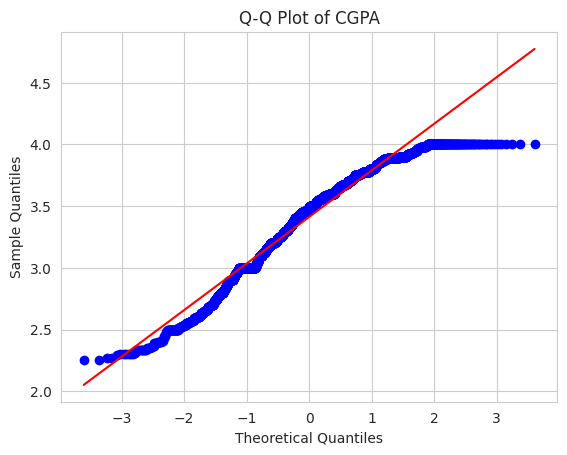

In [25]:
# Q-Q Plot: is CGPA normally distributed?
stats.probplot(raw["CGPA"], dist="norm", plot=plt)

plt.title("Q-Q Plot of CGPA")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()

Home_division
Dhaka         1527
Khulna         548
Rajshahi       488
Sylhet         445
Chittagong     400
Rangpur        363
Barisal        355
Mymensingh     338
Name: count, dtype: int64


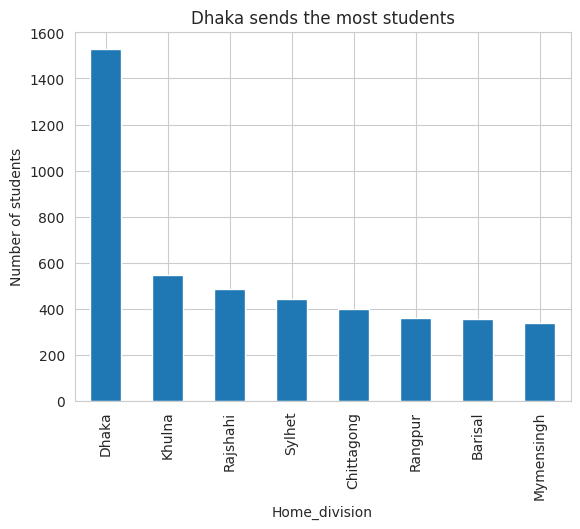

In [26]:
# BAR CHART: number of students from each division
division_count = raw["Home_division"].value_counts()
print(division_count)

division_count.plot(kind="bar")
plt.title("Dhaka sends the most students")
plt.ylabel("Number of students")
plt.show()

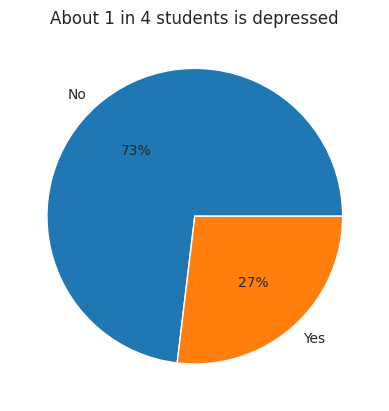

In [27]:
# PIE CHART: share of depressed students
dep_counts = raw["Depression"].value_counts()

plt.pie(dep_counts.values, labels=dep_counts.index, autopct="%1.0f%%")
plt.title("About 1 in 4 students is depressed")
plt.show()

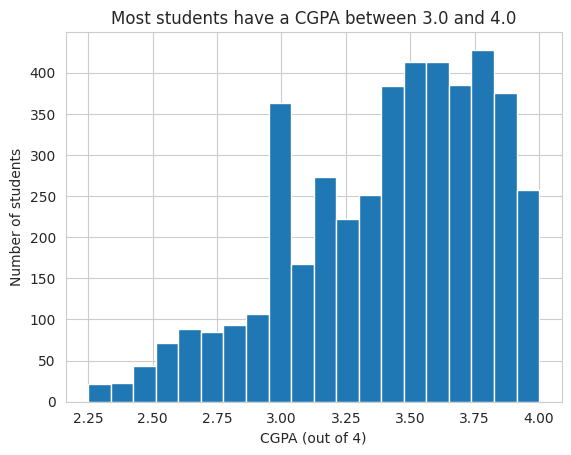

In [28]:
# HISTOGRAM
plt.hist(raw["CGPA"], bins=20)
plt.title("Most students have a CGPA between 3.0 and 4.0")
plt.xlabel("CGPA (out of 4)")
plt.ylabel("Number of students")
plt.show()

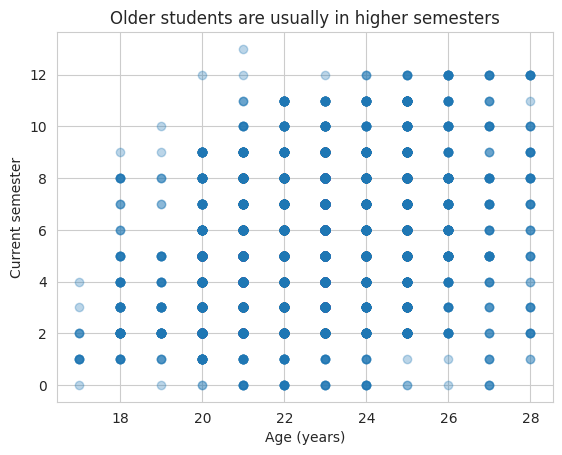

In [29]:
# SCATTER PLOT
plt.scatter(raw["Age"], raw["Current_semester"], alpha=0.3)
plt.title("Older students are usually in higher semesters")
plt.xlabel("Age (years)")
plt.ylabel("Current semester")
plt.show()

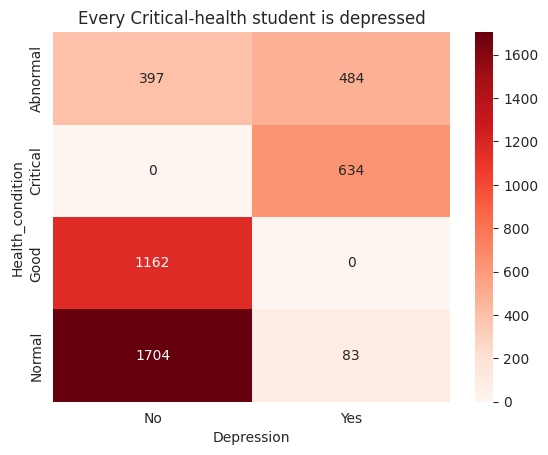

In [30]:
# HEATMAP: Health condition x Depression (counts)
health_dep = pd.crosstab(raw["Health_condition"], raw["Depression"])

sns.heatmap(health_dep, annot=True, fmt="d", cmap="Reds")
plt.title("Every Critical-health student is depressed")
plt.show()

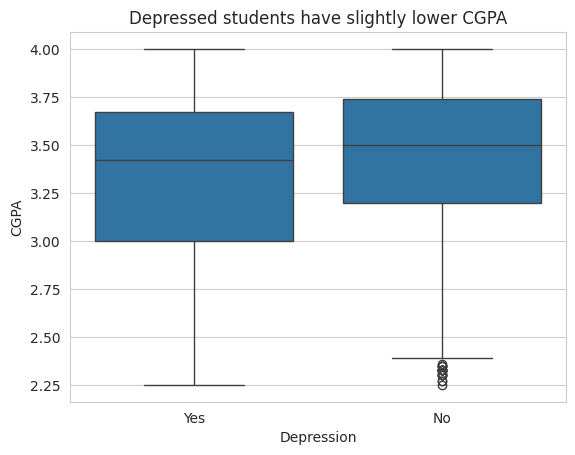

In [31]:
# BOXPLOT
sns.boxplot(data=raw, x="Depression", y="CGPA")
plt.title("Depressed students have slightly lower CGPA")
plt.show()

# Lecture 7 - Data quality: missing values and unusual values

In [32]:
# Check missing values and data types
raw.info()
raw.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


,0
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


In [33]:
# Percentage of missing values
total_blank = raw.isnull().sum().sum()

print("Blank cells :", total_blank)
print("Blank %     :", round(total_blank / raw.size * 100, 1), "%")
print("Rows with at least one blank:", raw.isnull().any(axis=1).sum(), "out of", len(raw))

Blank cells : 0
Blank %     : 0.0 %
Rows with at least one blank: 0 out of 4464


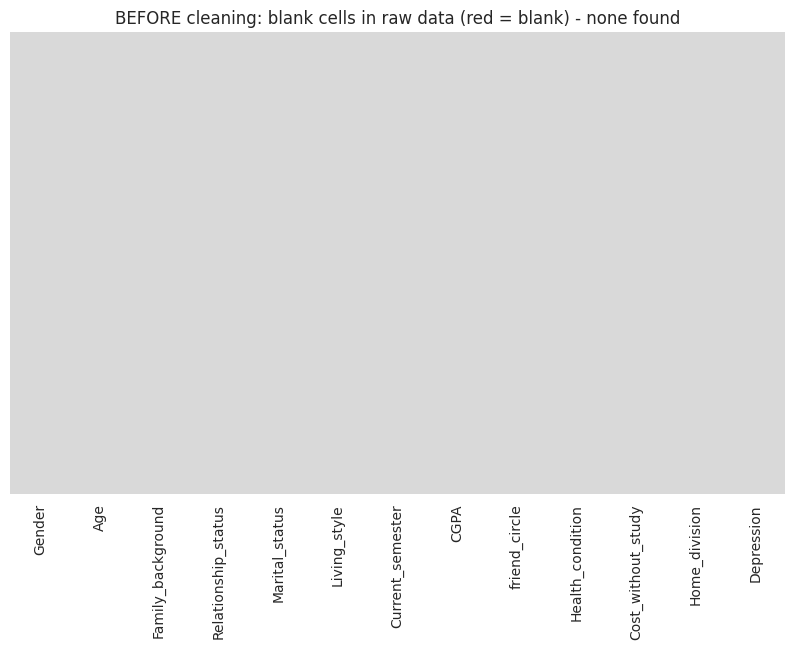

In [34]:
# Heatmap for missing values
from matplotlib.colors import ListedColormap

colors = ListedColormap(["#d9d9d9", "#fd2728"])

plt.figure(figsize=(10, 6))
sns.heatmap(raw.isnull(), cmap=colors, cbar=False, yticklabels=False)
plt.title("BEFORE cleaning: blank cells in raw data (red = blank) - none found")
plt.show()

# Inconsistent text entries (extra spaces, spelling)

In [35]:
# Look at every label in each text column
for col in category_cols:
    print(col, ":", raw[col].unique())

Gender : ['Female' 'Male']
Family_background : ['Middle class' 'Lower Middle class' 'Rich class']
Relationship_status : ['Single' 'Complicated' 'In a Relationship']
Marital_status : ['Unmarried' 'Married' 'Separated']
Living_style : ['Bachelor' 'Family']
friend_circle : ['Yes' 'No']
Health_condition : ['Critical' 'Abnormal' 'Good' 'Normal']
Home_division : ['Chittagong' 'Dhaka' 'Rajshahi' 'Mymensingh' 'Barisal' 'Rangpur' 'Khulna'
 'Sylhet']
Depression : ['Yes' 'No']


In [36]:
# Remove extra spaces from all text columns (safe step, changes nothing if already clean)
df = raw.copy()

for col in category_cols:
    df[col] = df[col].str.strip()

changed = (df[category_cols] != raw[category_cols]).sum().sum()
print("Text cells changed by strip():", changed)

Text cells changed by strip(): 0


In [37]:
# Logical check: a student who is Married but says relationship is Single
conflict = (df["Marital_status"] == "Married") & (df["Relationship_status"] == "Single")
print("Married but Single:", conflict.sum())

# We cannot know which answer is wrong, so we keep the rows and add a flag column
df["Status_Check"] = np.where(conflict, "Married but Single", "OK")
df["Status_Check"].value_counts()

Married but Single: 201


,count
Status_Check,
OK,4263
Married but Single,201


# Descriptive statistics: spot values that look wrong

In [38]:
df[number_cols].describe().round(1)

,Age,Current_semester,CGPA,Cost_without_study
count,4464.0,4464.0,4464.0,4464.0
mean,22.6,5.4,3.4,11243.0
std,2.0,2.6,0.4,6640.1
min,17.0,0.0,2.2,0.0
25%,21.0,3.0,3.2,6100.0
50%,23.0,5.0,3.5,9500.0
75%,24.0,7.0,3.7,15439.0
max,28.0,13.0,4.0,32000.0


# A big gap between mean and median is a warning sign

In [39]:
gap = pd.DataFrame({
    "Mean": df[number_cols].mean(),
    "Median": df[number_cols].median(),
})

gap["Gap %"] = ((gap["Mean"] - gap["Median"]) / gap["Median"] * 100).round(1)
gap.round(1)

,Mean,Median,Gap %
Age,22.6,23.0,-1.7
Current_semester,5.4,5.0,8.0
CGPA,3.4,3.5,-2.2
Cost_without_study,11243.0,9500.0,18.3


In [40]:
# Business rules: the allowed range of each number
rules = {
    "Age": (16, 35),                    # university students
    "Current_semester": (1, 13),        # a current student is in semester 1 or above
    "CGPA": (0, 4),                     # CGPA scale is 0 to 4
    "Cost_without_study": (0, 100000)   # monthly cost cannot be negative
}

for col, (low, high) in rules.items():
    bad = df[(df[col] < low) | (df[col] > high)]
    print(col, "-> impossible values:", len(bad))

Age -> impossible values: 0
Current_semester -> impossible values: 42
CGPA -> impossible values: 0
Cost_without_study -> impossible values: 0


# Boxplot of every numeric variable

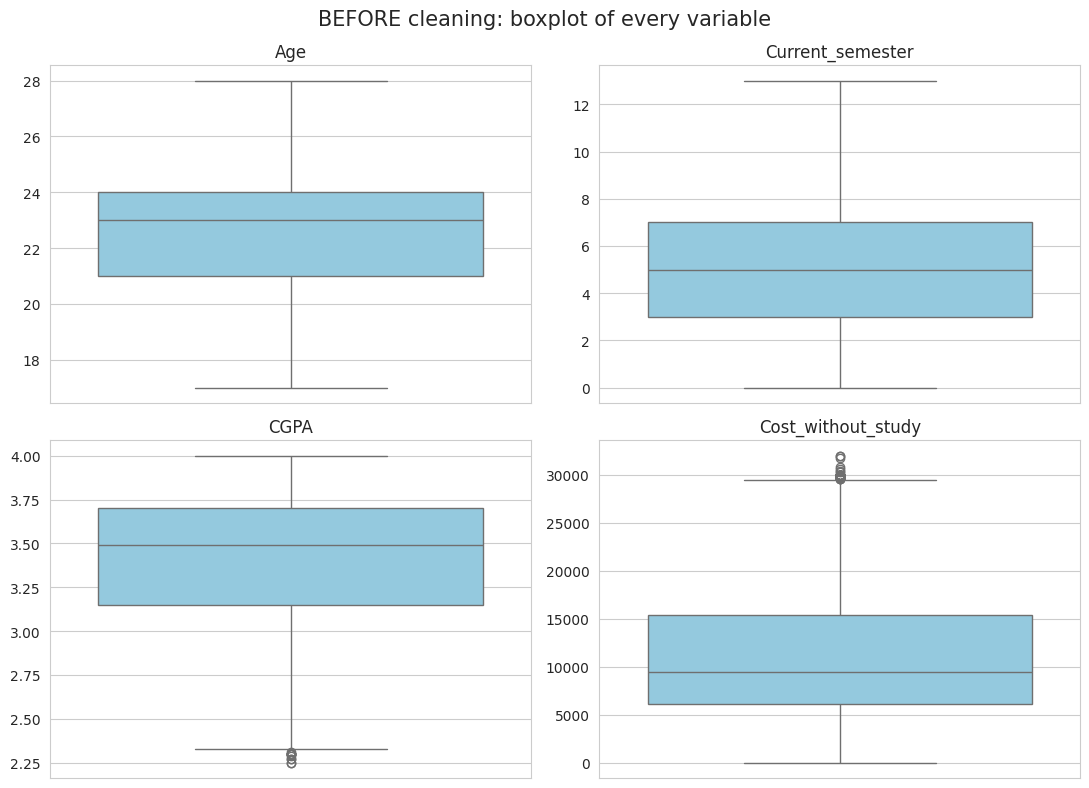

In [41]:
def show_boxplots(data, title):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    axes = axes.flatten()

    for i, col in enumerate(number_cols):
        sns.boxplot(y=data[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col)
        axes[i].set_ylabel("")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_boxplots(df, "BEFORE cleaning: boxplot of every variable")

# Replace impossible values with NaN

In [42]:
# Semester 0 is impossible for a current student
df["Current_semester"] = df["Current_semester"].astype(float)

for col, (low, high) in rules.items():
    bad_rows = (df[col] < low) | (df[col] > high)
    print(col, "-> removed", bad_rows.sum(), "impossible value(s)")
    df.loc[bad_rows, col] = np.nan

print()
print("Blank cells before:", raw.isnull().sum().sum())
print("Blank cells after :", df.isnull().sum().sum())

Age -> removed 0 impossible value(s)
Current_semester -> removed 42 impossible value(s)
CGPA -> removed 0 impossible value(s)
Cost_without_study -> removed 0 impossible value(s)

Blank cells before: 0
Blank cells after : 42


# Lecture 8 - Imputation: four methods, then we choose one

In [43]:
# Method 1: Remove rows containing missing values
df_drop = df.dropna()

print("Rows before:", len(df))
print("Rows after :", len(df_drop))
print("Data lost:", round((1 - len(df_drop) / len(df)) * 100, 1), "%")

Rows before: 4464
Rows after : 4422
Data lost: 0.9 %


In [44]:
# Method 2: Fill with the mean
df_mean = df.copy()
df_mean["Current_semester"] = df_mean["Current_semester"].fillna(df_mean["Current_semester"].mean())
print("Mean used  :", round(df["Current_semester"].mean(), 2), "-> not a whole semester, so not ideal")
print("Blanks left:", df_mean.isnull().sum().sum())

Mean used  : 5.45 -> not a whole semester, so not ideal
Blanks left: 0


In [45]:
# Method 3: Fill with the median
df_median = df.copy()
df_median["Current_semester"] = df_median["Current_semester"].fillna(df_median["Current_semester"].median())
print("Median used:", df["Current_semester"].median())
print("Blanks left:", df_median.isnull().sum().sum())

Median used: 5.0
Blanks left: 0


In [46]:
# Method 4: Fill with the mode (most common value)
df_mode = df.copy()
df_mode["Current_semester"] = df_mode["Current_semester"].fillna(df_mode["Current_semester"].mode()[0])
print("Mode used  :", df["Current_semester"].mode()[0])
print("Blanks left:", df_mode.isnull().sum().sum())

Mode used  : 5.0
Blanks left: 0


In [47]:
# Our choice: MEDIAN (a whole semester number, not affected by extremes, keeps all rows)
df["Current_semester"] = df["Current_semester"].fillna(df["Current_semester"].median()).astype(int)

print("Blanks left:", df.isnull().sum().sum())
print("Rows kept  :", len(df))

Blanks left: 0
Rows kept  : 4464


# Data capping (IQR method) - Cost_without_study

In [48]:
col = "Cost_without_study"

before = raw[col].copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1, "| Q3:", Q3, "| IQR:", IQR)
print("Lower fence:", lower, "| Upper fence:", upper)
print("Outliers found:", ((before < lower) | (before > upper)).sum())

# Apply capping
df[col] = before.clip(lower, upper)

comparison = pd.DataFrame({
    "Before Capping": before.describe(),
    "After Capping": df[col].describe()
})

print("Descriptive Statistics")
display(comparison.round(2))

print("Maximum before:", before.max())
print("Maximum after :", df[col].max())

Q1: 6100.0 | Q3: 15439.0 | IQR: 9339.0
Lower fence: -7908.5 | Upper fence: 29447.5
Outliers found: 36
Descriptive Statistics


,Before Capping,After Capping
count,4464.00,4464.00
mean,11242.98,11237.80
std,6640.14,6625.45
min,0.00,0.00
25%,6100.00,6100.00
50%,9500.00,9500.00
75%,15439.00,15439.00
max,32000.00,29447.50


Maximum before: 32000
Maximum after : 29447.5


In [49]:
# CGPA and Age: check outliers but KEEP them (low grades are real and important)
for col in ["CGPA", "Age"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, "| fences:", round(lower, 3), "to", round(upper, 3), "| outliers:", outliers, "-> retained")

CGPA | fences: 2.325 to 4.525 | outliers: 12 -> retained
Age | fences: 16.5 to 28.5 | outliers: 0 -> retained


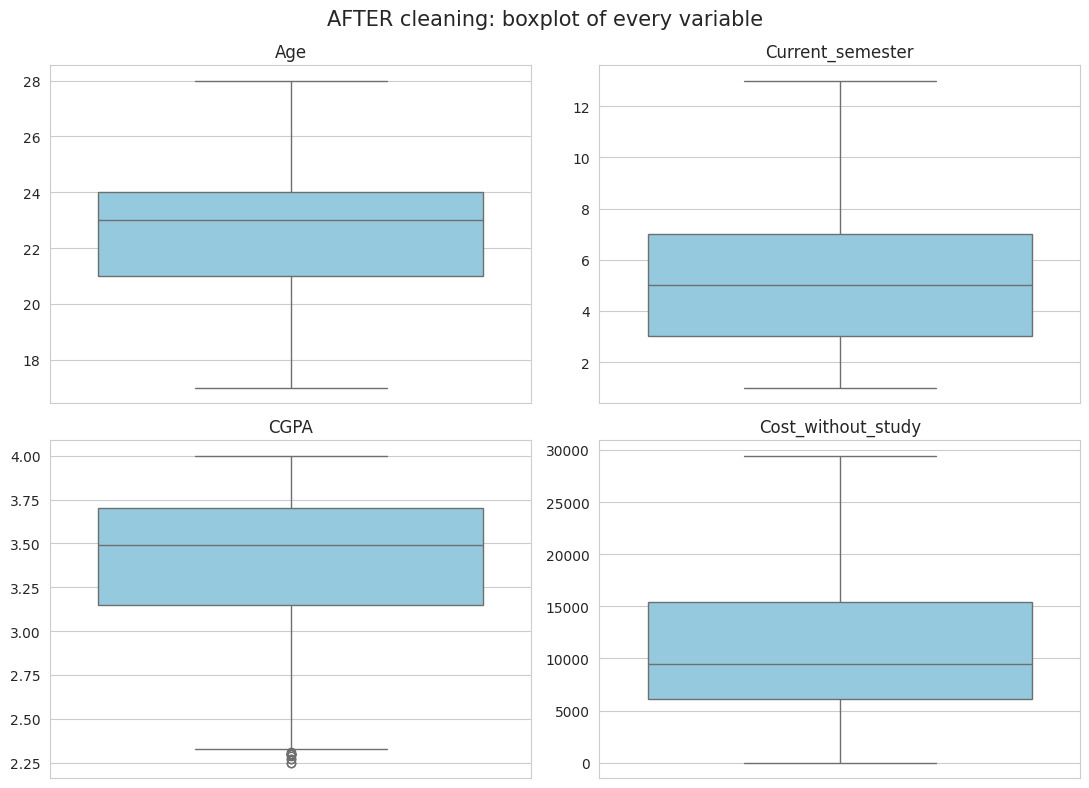

In [50]:
show_boxplots(df, "AFTER cleaning: boxplot of every variable")

# Add number columns so we can do maths on text answers

In [51]:
df["Depression_Flag"] = (df["Depression"] == "Yes").astype(int)      # 1 = Yes, 0 = No
df["Health_Score"] = df["Health_condition"].map(health_score)        # uses our dictionary
df["Friend_Flag"] = (df["friend_circle"] == "Yes").astype(int)
df["Bachelor_Flag"] = (df["Living_style"] == "Bachelor").astype(int)

df[["Depression", "Depression_Flag", "Health_condition", "Health_Score"]].head()

,Depression,Depression_Flag,Health_condition,Health_Score
0,Yes,1,Critical,1
1,Yes,1,Abnormal,2
2,Yes,1,Abnormal,2
3,No,0,Good,4
4,Yes,1,Abnormal,2


In [52]:
# Before vs after cleaning
summary = pd.DataFrame({
    "Before cleaning": [len(raw), raw.isnull().sum().sum(), raw.duplicated().sum(),
                        (raw["Current_semester"] == 0).sum(), raw["Cost_without_study"].max()],
    "After cleaning": [len(df), df.isnull().sum().sum(), df.duplicated().sum(),
                       (df["Current_semester"] == 0).sum(), df["Cost_without_study"].max()]
}, index=["Rows", "Missing cells", "Duplicate rows", "Semester = 0", "Max living cost"])

summary

,Before cleaning,After cleaning
Rows,4464,4464.0
Missing cells,0,0.0
Duplicate rows,0,0.0
Semester = 0,42,0.0
Max living cost,32000,29447.5


In [53]:
# Check: our cleaned data matches the Cleaned_Data sheet in the Excel file
excel_clean = pd.read_excel(FILE, sheet_name="Cleaned_Data")
print("Same as Excel Cleaned_Data sheet?", np.allclose(df[number_cols], excel_clean[number_cols]))

Same as Excel Cleaned_Data sheet? True


# Group-wise summaries (groupby)

In [54]:
# 1. Depression rate by health condition
health_rate = df.groupby("Health_condition")["Depression_Flag"].mean().sort_values(ascending=False) * 100
print(health_rate.round(1))

Health_condition
Critical    100.0
Abnormal     54.9
Normal        4.6
Good          0.0
Name: Depression_Flag, dtype: float64


In [55]:
# 2. Depression rate by friend circle, family background and relationship status
for col in ["friend_circle", "Family_background", "Relationship_status", "Marital_status", "Living_style", "Gender"]:
    print((df.groupby(col)["Depression_Flag"].mean() * 100).round(1))
    print()

friend_circle
No     34.3
Yes    24.0
Name: Depression_Flag, dtype: float64

Family_background
Lower Middle class    30.6
Middle class          27.7
Rich class            17.6
Name: Depression_Flag, dtype: float64

Relationship_status
Complicated          13.2
In a Relationship    11.5
Single               35.9
Name: Depression_Flag, dtype: float64

Marital_status
Married      12.0
Separated    20.0
Unmarried    30.1
Name: Depression_Flag, dtype: float64

Living_style
Bachelor    28.3
Family      25.2
Name: Depression_Flag, dtype: float64

Gender
Female    26.6
Male      27.3
Name: Depression_Flag, dtype: float64



In [56]:
# 3. Average CGPA and depression rate by home division
division_summary = df.groupby("Home_division").agg(
    Students=("Depression_Flag", "count"),
    Depression_Rate=("Depression_Flag", "mean"),
    Avg_CGPA=("CGPA", "mean"),
    Avg_Cost=("Cost_without_study", "mean")
).sort_values("Depression_Rate", ascending=False)

division_summary["Depression_Rate"] = division_summary["Depression_Rate"] * 100
division_summary.round(2)

,Students,Depression_Rate,Avg_CGPA,Avg_Cost
Home_division,,,,
Rangpur,363,31.96,3.37,9770.29
Rajshahi,488,31.56,3.43,11859.88
Khulna,548,31.02,3.45,13084.58
Chittagong,400,30.50,3.45,12841.08
Mymensingh,338,27.81,3.43,11731.53
Barisal,355,27.61,3.40,11707.49
Sylhet,445,23.60,3.35,11065.36
Dhaka,1527,22.40,3.41,10136.89


# Lecture 10 - Visualisation with a business question

# Business question: how are CGPAs spread, and how many are below 3.0?

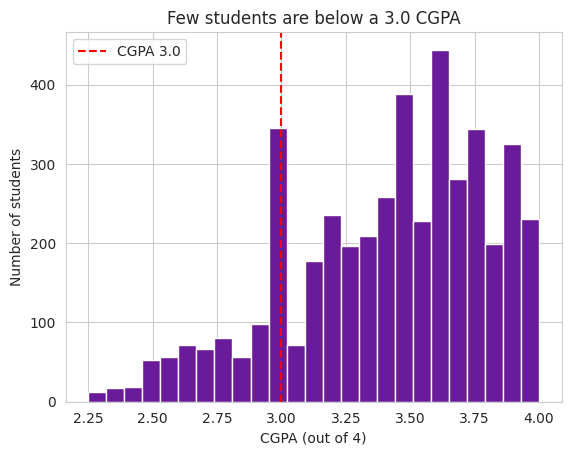

In [57]:
plt.hist(df["CGPA"], bins=25, color="#6A1B9A", edgecolor="white")
plt.axvline(3.0, color="red", linestyle="--", label="CGPA 3.0")
plt.title("Few students are below a 3.0 CGPA")
plt.xlabel("CGPA (out of 4)")
plt.ylabel("Number of students")
plt.legend()
plt.show()

# Business question: which family background has the highest depression rate?

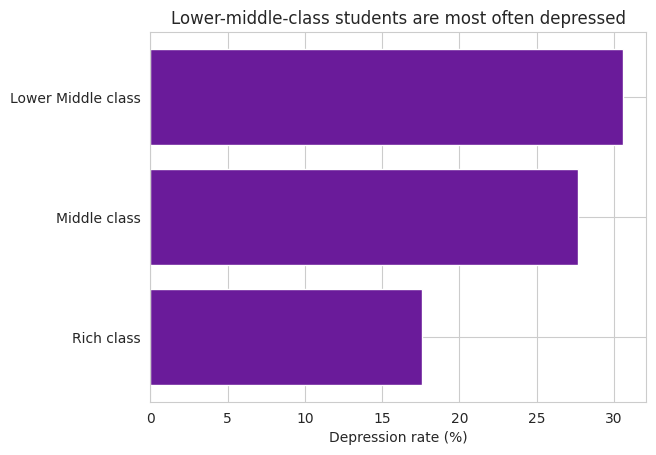

In [58]:
family_rate = df.groupby("Family_background")["Depression_Flag"].mean().sort_values() * 100

plt.barh(family_rate.index, family_rate.values, color="#6A1B9A")
plt.title("Lower-middle-class students are most often depressed")
plt.xlabel("Depression rate (%)")
plt.show()

# Business question: does depression rise or fall as students move through semesters? (line plot)

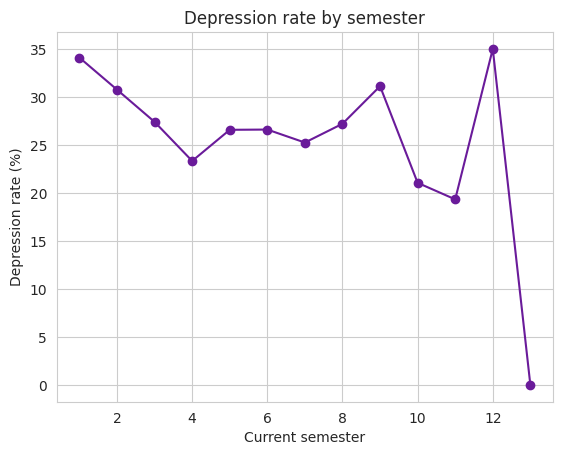

In [59]:
sem_rate = df.groupby("Current_semester")["Depression_Flag"].mean() * 100

plt.plot(sem_rate.index, sem_rate.values, marker="o", color="#6A1B9A")
plt.title("Depression rate by semester")
plt.xlabel("Current semester")
plt.ylabel("Depression rate (%)")
plt.show()

# Business question: in which semesters are most depressed students? (area plot)

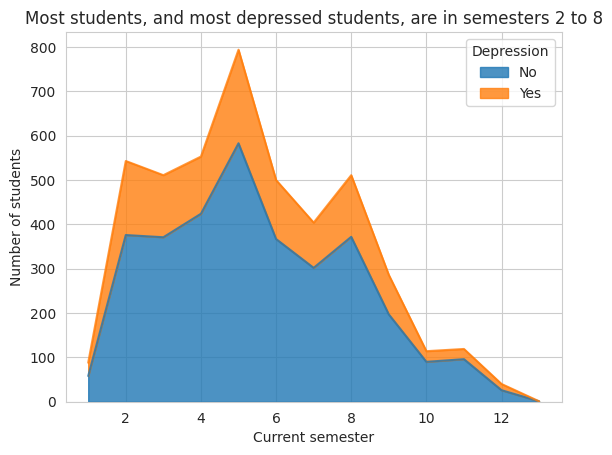

In [60]:
sem_dep = df.pivot_table(index="Current_semester", columns="Depression", values="Age", aggfunc="count").fillna(0)

sem_dep.plot(kind="area", alpha=0.8)
plt.title("Most students, and most depressed students, are in semesters 2 to 8")
plt.xlabel("Current semester")
plt.ylabel("Number of students")
plt.show()

# Business question: do students who spend more have higher CGPA? (scatter)

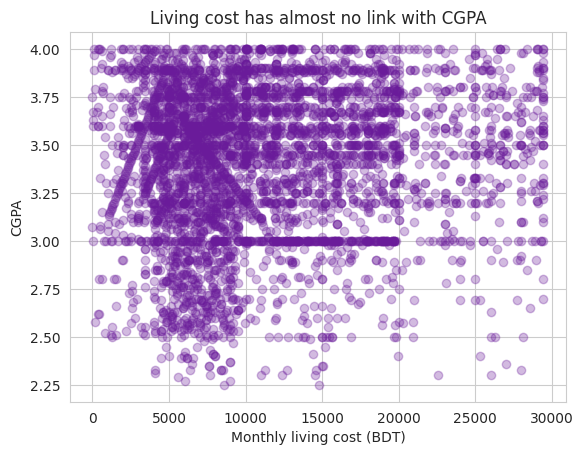

In [61]:
plt.scatter(df["Cost_without_study"], df["CGPA"], alpha=0.3, color="#6A1B9A")
plt.title("Living cost has almost no link with CGPA")
plt.xlabel("Monthly living cost (BDT)")
plt.ylabel("CGPA")
plt.show()

# Quiver plot: what changes when students live away from family (Family -> Bachelor) in each division?

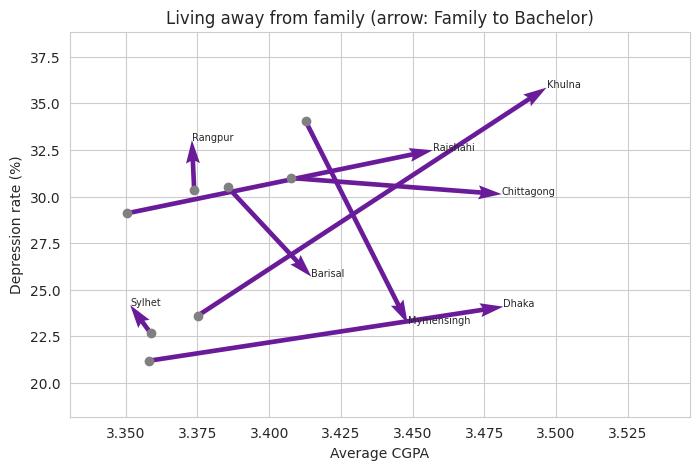

In [62]:
means = df.groupby(["Home_division", "Living_style"])[["CGPA", "Depression_Flag"]].mean().reset_index()

family = means[means["Living_style"] == "Family"].set_index("Home_division")
bachelor = means[means["Living_style"] == "Bachelor"].set_index("Home_division")

x = family["CGPA"]
y = family["Depression_Flag"] * 100
dx = bachelor["CGPA"] - family["CGPA"]
dy = (bachelor["Depression_Flag"] - family["Depression_Flag"]) * 100

plt.figure(figsize=(8, 5))
plt.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1, color="#6A1B9A")
plt.scatter(x, y, color="grey")

for name in family.index:
    plt.text(x[name] + dx[name], y[name] + dy[name], name, fontsize=7)

plt.xlim(min(x.min(), (x + dx).min()) - 0.02, max(x.max(), (x + dx).max()) + 0.05)
plt.ylim(min(y.min(), (y + dy).min()) - 3, max(y.max(), (y + dy).max()) + 3)
plt.title("Living away from family (arrow: Family to Bachelor)")
plt.xlabel("Average CGPA")
plt.ylabel("Depression rate (%)")
plt.show()

# Business question: for a given CGPA and health score, how likely is depression? (meshgrid + contour)

In [63]:
# A tiny example of meshgrid first
a = np.array([1, 2, 3])
b = np.array([5, 10])
A, B = np.meshgrid(a, b)
print(A)
print(B)

[[1 2 3]
 [1 2 3]]
[[ 5  5  5]
 [10 10 10]]


Each extra CGPA point changes depression chance by -7.7 percentage points
Each step better in health changes it by -34.0 percentage points


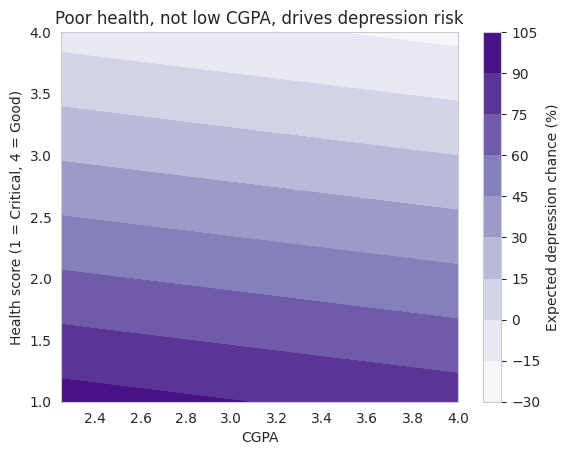

In [64]:
from sklearn.linear_model import LinearRegression

# Step 1: A simple formula from our data
formula = LinearRegression().fit(df[["CGPA", "Health_Score"]], df["Depression_Flag"])

print("Each extra CGPA point changes depression chance by", round(formula.coef_[0] * 100, 1), "percentage points")
print("Each step better in health changes it by", round(formula.coef_[1] * 100, 1), "percentage points")

# Step 2: All what-if cases
cgpa_values = np.linspace(2.25, 4.0, 40)
health_values = np.linspace(1, 4, 40)
C, H = np.meshgrid(cgpa_values, health_values)

cases = pd.DataFrame({"CGPA": C.ravel(), "Health_Score": H.ravel()})
P = formula.predict(cases).reshape(C.shape) * 100

# Step 3: Contour plot
plt.contourf(C, H, P, levels=10, cmap="Purples")
plt.colorbar(label="Expected depression chance (%)")
plt.title("Poor health, not low CGPA, drives depression risk")
plt.xlabel("CGPA")
plt.ylabel("Health score (1 = Critical, 4 = Good)")
plt.show()

# Lecture 11 - Animation and Seaborn charts

In [65]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Running total of depressed students, semester by semester, for each division
running = df[df["Depression_Flag"] == 1].pivot_table(
    index="Current_semester", columns="Home_division", values="Age", aggfunc="count").fillna(0).cumsum()
running = running.loc[:, running.iloc[-1].sort_values().index]   # smallest to largest

fig, ax = plt.subplots(figsize=(7, 5))

def draw(i):
    ax.clear()
    ax.barh(running.columns, running.iloc[i], color="#6A1B9A")
    ax.set_xlim(0, running.values.max() * 1.1)
    ax.set_title("Depressed students up to semester " + str(running.index[i]))
    ax.set_xlabel("Number of depressed students")

animation = FuncAnimation(fig, draw, frames=len(running), interval=700)

plt.close()
HTML(animation.to_jshtml())   # press the play button

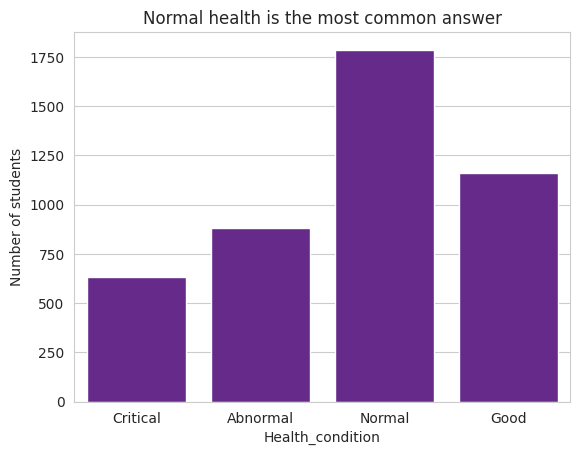

In [66]:
# COUNT PLOT
health_order = ["Critical", "Abnormal", "Normal", "Good"]

sns.countplot(data=df, x="Health_condition", order=health_order, color="#6A1B9A")
plt.title("Normal health is the most common answer")
plt.ylabel("Number of students")
plt.show()

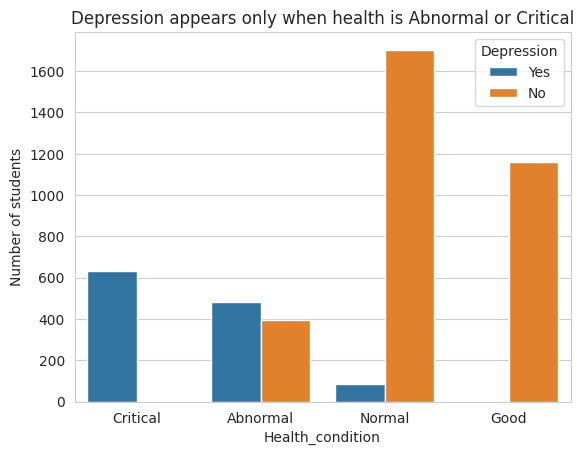

In [67]:
# COUNT PLOT with hue
sns.countplot(data=df, x="Health_condition", order=health_order, hue="Depression")
plt.title("Depression appears only when health is Abnormal or Critical")
plt.ylabel("Number of students")
plt.show()

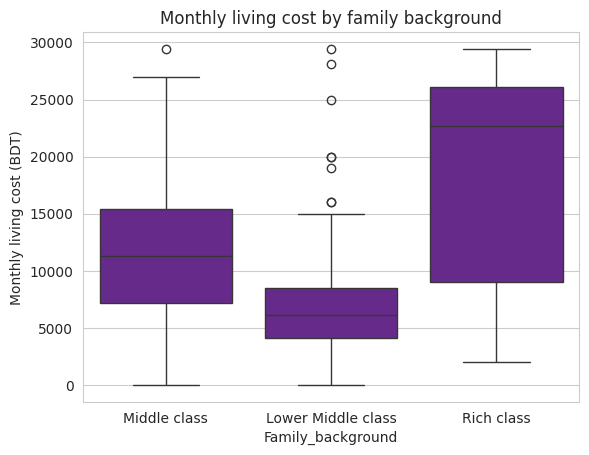

In [68]:
# BOX PLOT (Seaborn)
sns.boxplot(data=df, x="Family_background", y="Cost_without_study", color="#6A1B9A")
plt.title("Monthly living cost by family background")
plt.ylabel("Monthly living cost (BDT)")
plt.show()

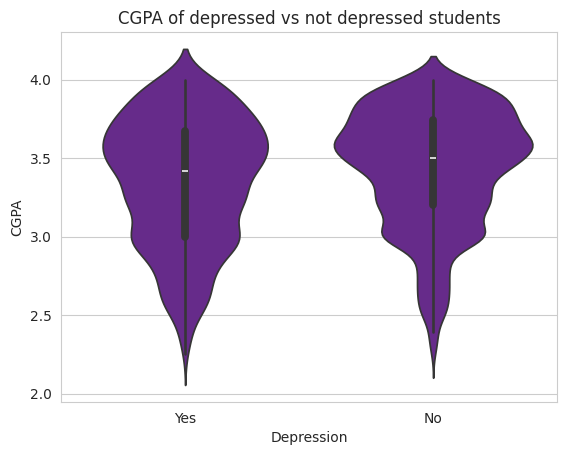

In [69]:
# VIOLIN PLOT: do depressed students have a different CGPA shape?
sns.violinplot(data=df, x="Depression", y="CGPA", color="#6A1B9A")
plt.title("CGPA of depressed vs not depressed students")
plt.ylabel("CGPA")
plt.show()

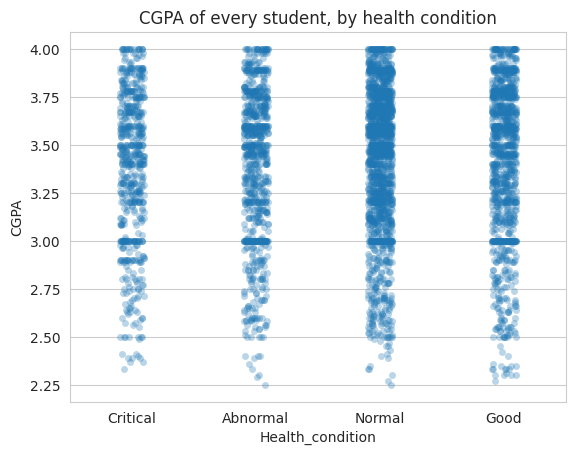

In [70]:
# STRIP PLOT: CGPA of every student by health condition
sns.stripplot(data=df, x="Health_condition", y="CGPA", order=health_order, jitter=True, alpha=0.3)
plt.title("CGPA of every student, by health condition")
plt.ylabel("CGPA")
plt.show()

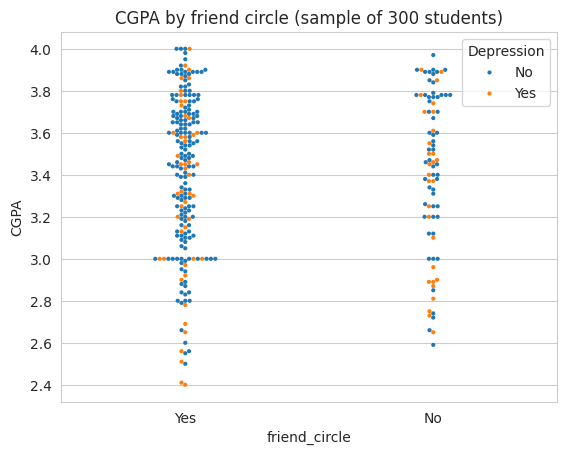

In [71]:
# SWARM PLOT (on a sample of 300 students so it draws quickly)
sample = df.sample(300, random_state=1)

sns.swarmplot(data=sample, x="friend_circle", y="CGPA", hue="Depression", size=3)
plt.title("CGPA by friend circle (sample of 300 students)")
plt.show()

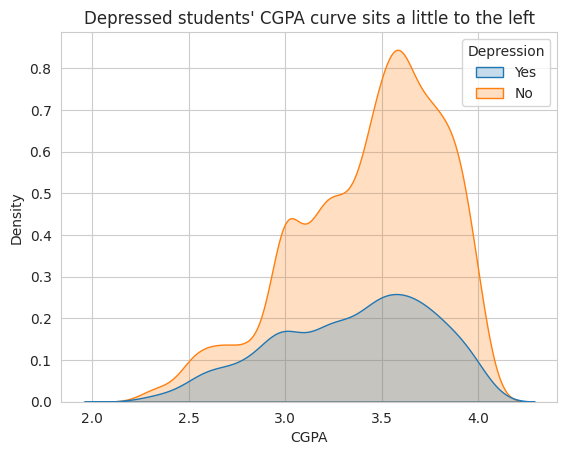

In [72]:
# DISTRIBUTION (KDE) PLOT
sns.kdeplot(data=df, x="CGPA", hue="Depression", fill=True)
plt.title("Depressed students' CGPA curve sits a little to the left")
plt.xlabel("CGPA")
plt.show()

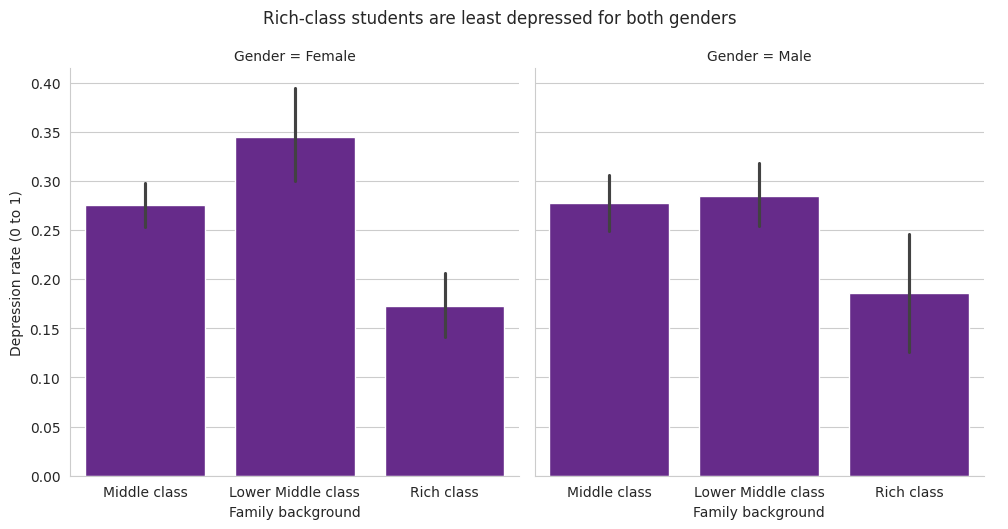

In [73]:
# FACTOR PLOT / FacetGrid (catplot): depression by family background, split by gender
g = sns.catplot(data=df, x="Family_background", y="Depression_Flag", col="Gender", kind="bar", color="#6A1B9A")
g.set_axis_labels("Family background", "Depression rate (0 to 1)")
g.fig.suptitle("Rich-class students are least depressed for both genders", y=1.05)
plt.show()

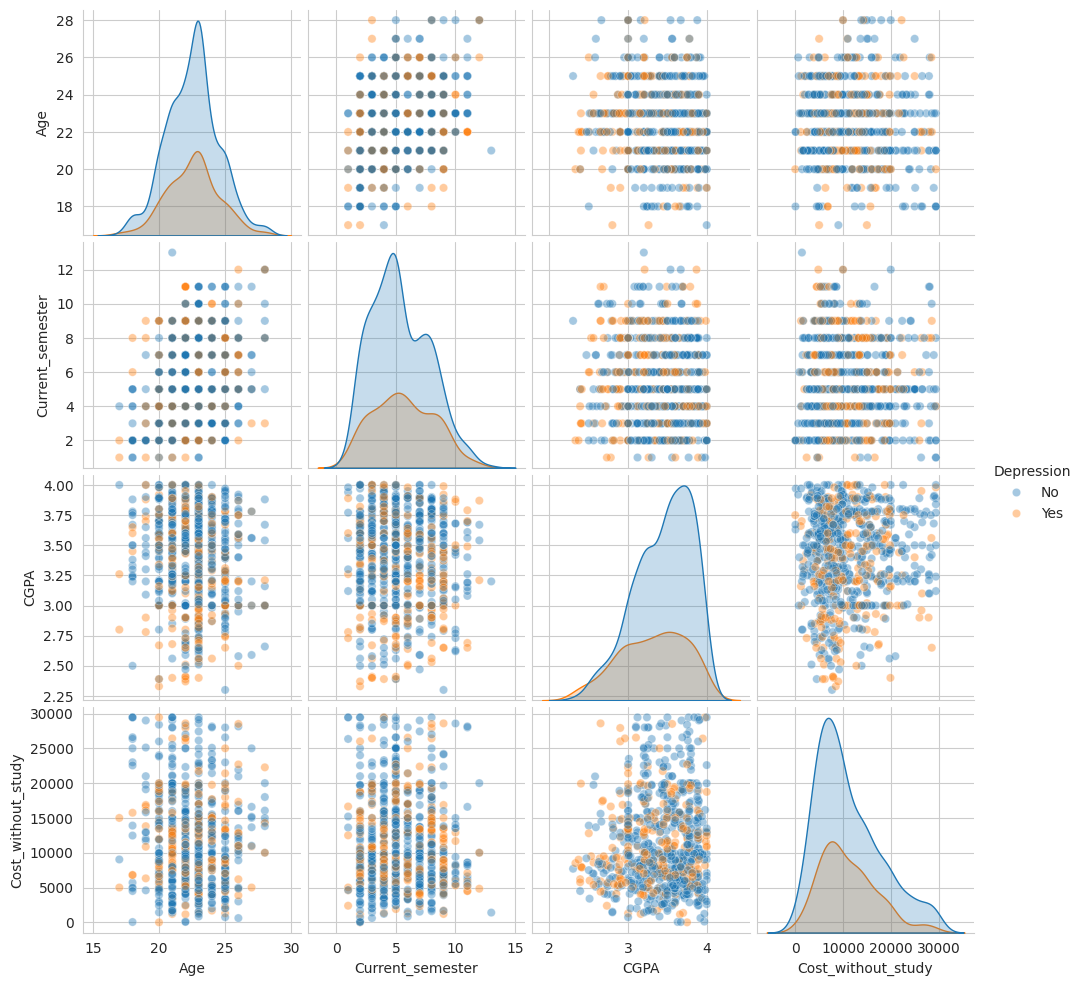

In [74]:
# PAIR PLOT
sns.pairplot(df[["Age", "Current_semester", "CGPA", "Cost_without_study", "Depression"]].sample(800, random_state=1),
             hue="Depression", plot_kws={"alpha": 0.4})
plt.show()

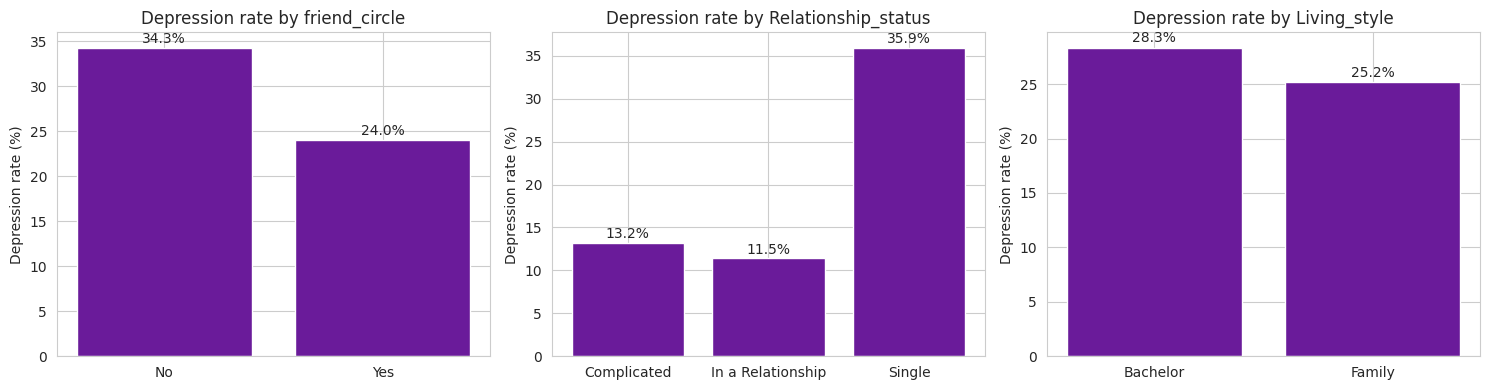

In [75]:
# MULTI-PANEL (subplots) with annotations
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

panels = ["friend_circle", "Relationship_status", "Living_style"]

for i, col in enumerate(panels):
    rate = df.groupby(col)["Depression_Flag"].mean() * 100
    axes[i].bar(rate.index, rate.values, color="#6A1B9A")
    axes[i].set_title("Depression rate by " + col)
    axes[i].set_ylabel("Depression rate (%)")

    for j, value in enumerate(rate.values):
        axes[i].annotate(str(round(value, 1)) + "%", (j, value + 0.5), ha="center")

plt.tight_layout()
plt.show()

# Lecture 11 - Statistical summaries

In [76]:
for col in ["CGPA", "Cost_without_study", "Age"]:
    print(col)
    print("  Mean     :", round(df[col].mean(), 2))
    print("  Median   :", df[col].median())
    print("  Mode     :", df[col].mode()[0])
    print("  Variance :", round(df[col].var(), 2))
    print("  Std dev  :", round(df[col].std(), 2))
    print("  Q1       :", df[col].quantile(0.25))
    print("  Q3       :", df[col].quantile(0.75))
    print()

print("Mode of Health_condition:", df["Health_condition"].mode()[0])
print("Mode of Home_division   :", df["Home_division"].mode()[0])

CGPA
  Mean     : 3.41
  Median   : 3.49
  Mode     : 3.0
  Variance : 0.15
  Std dev  : 0.39
  Q1       : 3.15
  Q3       : 3.7

Cost_without_study
  Mean     : 11237.8
  Median   : 9500.0
  Mode     : 10000.0
  Variance : 43896621.45
  Std dev  : 6625.45
  Q1       : 6100.0
  Q3       : 15439.0

Age
  Mean     : 22.62
  Median   : 23.0
  Mode     : 23.0
  Variance : 4.09
  Std dev  : 2.02
  Q1       : 21.0
  Q3       : 24.0

Mode of Health_condition: Normal
Mode of Home_division   : Dhaka


# Lecture 12 - Relationships between variables (correlation)

In [77]:
numbers = df.select_dtypes(include="number").columns.tolist()
categories = df.select_dtypes(exclude="number").columns.tolist()

print("Number Variables:", len(numbers), numbers)
print("Category Variables:", len(categories), categories)

Number Variables: 8 ['Age', 'Current_semester', 'CGPA', 'Cost_without_study', 'Depression_Flag', 'Health_Score', 'Friend_Flag', 'Bachelor_Flag']
Category Variables: 10 ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division', 'Depression', 'Status_Check']


In [78]:
# The key variables we will relate
key_cols = [
    "Age",
    "Current_semester",
    "CGPA",
    "Cost_without_study",
    "Health_Score",
    "Friend_Flag",
    "Bachelor_Flag",
    "Depression_Flag"
]

# Positive relationship: are older students in higher semesters?

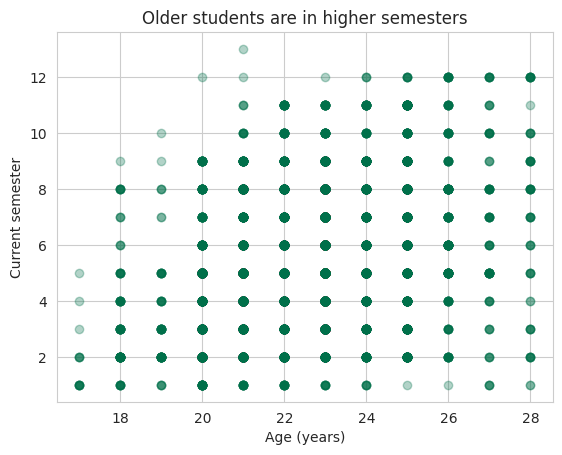

In [79]:
plt.scatter(df["Age"], df["Current_semester"], alpha=0.3, color="#00704A")
plt.title("Older students are in higher semesters")
plt.xlabel("Age (years)")
plt.ylabel("Current semester")
plt.show()

# Negative relationship: does better health mean less depression?

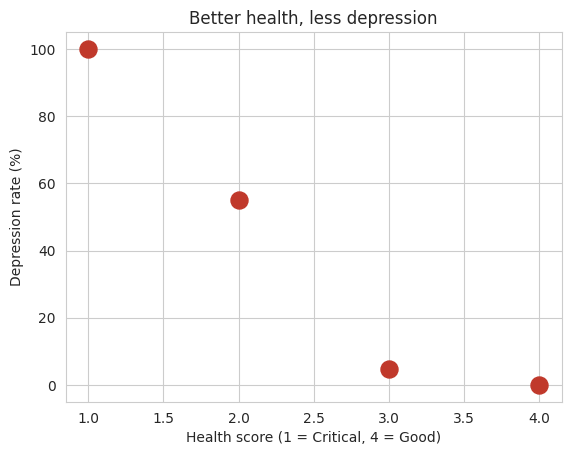

In [80]:
health_rate = df.groupby("Health_Score")["Depression_Flag"].mean() * 100

plt.scatter(health_rate.index, health_rate.values, s=150, color="#C0392B")
plt.title("Better health, less depression")
plt.xlabel("Health score (1 = Critical, 4 = Good)")
plt.ylabel("Depression rate (%)")
plt.show()

# Neutral relationship: does living cost affect CGPA?

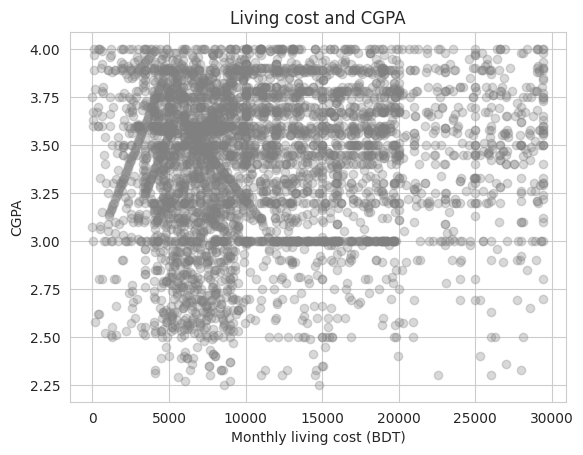

In [81]:
plt.scatter(df["Cost_without_study"], df["CGPA"], alpha=0.3, color="grey")
plt.title("Living cost and CGPA")
plt.xlabel("Monthly living cost (BDT)")
plt.ylabel("CGPA")
plt.show()

In [82]:
# Correlation coefficients - how strong is each relationship?
r1 = df["Age"].corr(df["Current_semester"])
r2 = df["Health_Score"].corr(df["Depression_Flag"])
r3 = df["Cost_without_study"].corr(df["CGPA"])

print("Age and semester         :", round(r1, 2))
print("Health and depression    :", round(r2, 2))
print("Living cost and CGPA     :", round(r3, 2))

Age and semester         : 0.33
Health and depression    : -0.76
Living cost and CGPA     : 0.08


# Overall correlation matrix

In [83]:
corr = df[key_cols].corr().round(2)
corr

,Age,Current_semester,CGPA,Cost_without_study,Health_Score,Friend_Flag,Bachelor_Flag,Depression_Flag
Age,1.00,0.33,-0.07,-0.06,0.01,-0.01,-0.18,-0.03
Current_semester,0.33,1.00,-0.01,0.01,0.03,0.01,-0.06,-0.02
CGPA,-0.07,-0.01,1.00,0.08,0.04,0.04,0.10,-0.10
Cost_without_study,-0.06,0.01,0.08,1.00,-0.11,-0.06,0.11,0.02
Health_Score,0.01,0.03,0.04,-0.11,1.00,0.05,-0.03,-0.76
Friend_Flag,-0.01,0.01,0.04,-0.06,0.05,1.00,0.07,-0.10
Bachelor_Flag,-0.18,-0.06,0.10,0.11,-0.03,0.07,1.00,0.04
Depression_Flag,-0.03,-0.02,-0.10,0.02,-0.76,-0.10,0.04,1.00


# Heatmap - where are the strong and weak relationships?

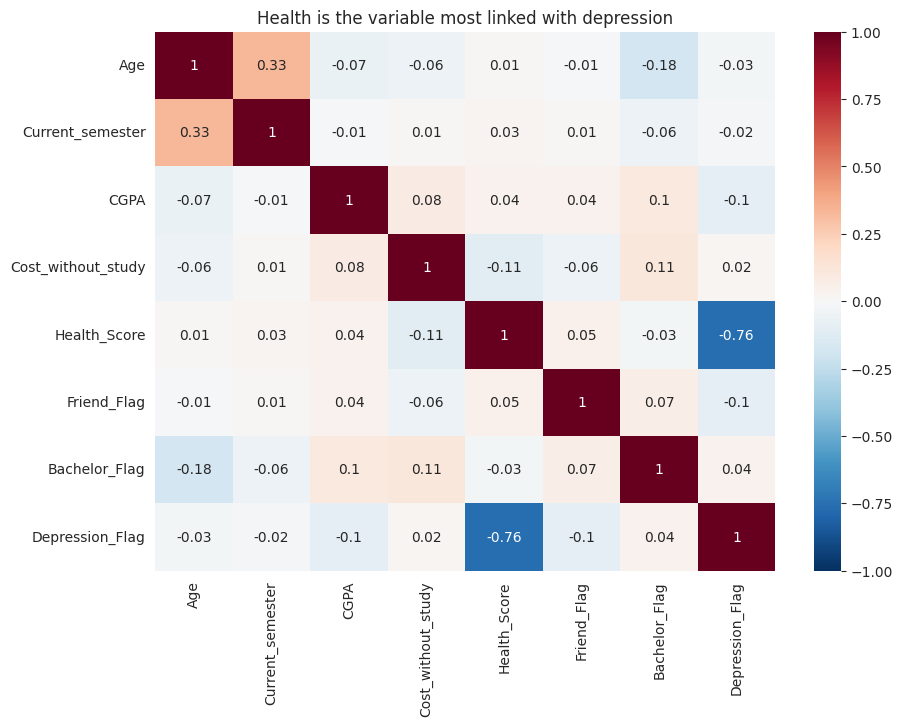

In [84]:
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Health is the variable most linked with depression")
plt.show()

In [85]:
# The three strongest relationships (ignoring a variable with itself)
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
pairs.head(3)

Health_Score  Depression_Flag    -0.76
Age           Current_semester    0.33
              Bachelor_Flag      -0.18
dtype: float64

# Lecture 13 - Statistical modelling: linear regression and multiple regression

Note: our dependent variable Depression_Flag is 0 or 1, so a coefficient means the change in the **chance** of depression (x 100 = percentage points).

In [86]:
import statsmodels.formula.api as smf

m_health = smf.ols("Depression_Flag ~ Health_Score", data=df).fit()

print(m_health.summary().tables[1])
print("R-squared:", round(m_health.rsquared, 2))

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.2163      0.013     94.415      0.000       1.191       1.242
Health_Score    -0.3409      0.004    -78.043      0.000      -0.349      -0.332
R-squared: 0.58


# Interpretation - write in your own words: what does a one-step better health score do to the chance of depression? How much does health explain (R-squared)? Is the p-value below 0.05?

# Another negative relationship: friend circle and depression

In [87]:
m_friend = smf.ols("Depression_Flag ~ Friend_Flag", data=df).fit()

print(m_friend.summary().tables[1])
print("R-squared:", round(m_friend.rsquared, 2))

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.3427      0.012     27.450      0.000       0.318       0.367
Friend_Flag    -0.1022      0.015     -6.950      0.000      -0.131      -0.073
R-squared: 0.01


# Multiple linear regression - what else affects depression?

In [88]:
m_multi = smf.ols(
    "Depression_Flag ~ Health_Score + Friend_Flag + CGPA + Bachelor_Flag + Cost_without_study",
    data=df
).fit()

print(m_multi.summary().tables[1])
print("R-squared:", round(m_multi.rsquared, 2))

                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              1.5426      0.040     38.578      0.000       1.464       1.621
Health_Score          -0.3412      0.004    -78.629      0.000      -0.350      -0.333
Friend_Flag           -0.0659      0.010     -6.905      0.000      -0.085      -0.047
CGPA                  -0.0704      0.011     -6.321      0.000      -0.092      -0.049
Bachelor_Flag          0.0253      0.009      2.922      0.003       0.008       0.042
Cost_without_study -4.596e-06   6.53e-07     -7.042      0.000   -5.88e-06   -3.32e-06
R-squared: 0.59


# Linear regression with a control variable - does CGPA still matter once health is held fixed?

In [89]:
m_cgpa_alone = smf.ols("Depression_Flag ~ CGPA", data=df).fit()
m_cgpa_ctrl = smf.ols("Depression_Flag ~ CGPA + Health_Score", data=df).fit()

print(m_cgpa_alone.summary().tables[1])
print("R-squared:", round(m_cgpa_alone.rsquared, 2))

print(m_cgpa_ctrl.summary().tables[1])
print("R-squared:", round(m_cgpa_ctrl.rsquared, 2))

print("CGPA effect alone      :", round(m_cgpa_alone.params["CGPA"], 3),
      "| p-value:", round(m_cgpa_alone.pvalues["CGPA"], 3))
print("CGPA effect with health:", round(m_cgpa_ctrl.params["CGPA"], 3),
      "| p-value:", round(m_cgpa_ctrl.pvalues["CGPA"], 3))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.6469      0.059     10.990      0.000       0.532       0.762
CGPA          -0.1107      0.017     -6.460      0.000      -0.144      -0.077
R-squared: 0.01
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.4759      0.040     37.178      0.000       1.398       1.554
CGPA            -0.0770      0.011     -6.910      0.000      -0.099      -0.055
Health_Score    -0.3397      0.004    -78.125      0.000      -0.348      -0.331
R-squared: 0.58
CGPA effect alone      : -0.111 | p-value: 0.0
CGPA effect with health: -0.077 | p-value: 0.0


# Linear regression with a moderation effect

# Step 1: centre the numbers (subtract the average)

In [90]:
df["CGPA_c"] = df["CGPA"] - df["CGPA"].mean()
df["Health_c"] = df["Health_Score"] - df["Health_Score"].mean()

# Does the effect of a friend circle depend on whether the student lives away from family?

In [91]:
m_mod = smf.ols("Depression_Flag ~ Friend_Flag * Bachelor_Flag", data=df).fit()

print(m_mod.summary().tables[1])
print("R-squared:", round(m_mod.rsquared, 2))

                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                     0.3564      0.017     20.424      0.000       0.322       0.391
Friend_Flag                  -0.1532      0.021     -7.259      0.000      -0.195      -0.112
Bachelor_Flag                -0.0279      0.025     -1.120      0.263      -0.077       0.021
Friend_Flag:Bachelor_Flag     0.0931      0.029      3.161      0.002       0.035       0.151
R-squared: 0.01


In [92]:
# Does the effect of CGPA depend on health?
m_mod2 = smf.ols("Depression_Flag ~ CGPA_c * Health_c", data=df).fit()

print(m_mod2.summary().tables[1])
print("R-squared:", round(m_mod2.rsquared, 2))

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.2689      0.004     62.565      0.000       0.260       0.277
CGPA_c             -0.0771      0.011     -6.913      0.000      -0.099      -0.055
Health_c           -0.3396      0.004    -78.081      0.000      -0.348      -0.331
CGPA_c:Health_c     0.0112      0.011      1.010      0.313      -0.011       0.033
R-squared: 0.58


# Visualisation: CGPA and depression, for good vs poor health

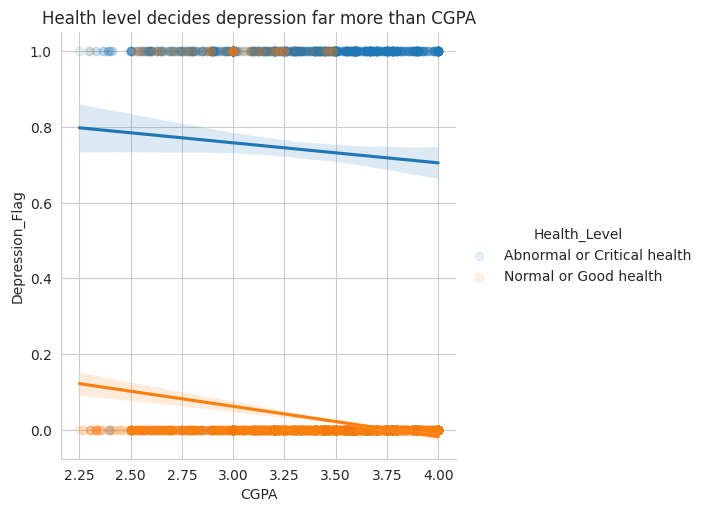

In [93]:
df["Health_Level"] = np.where(df["Health_Score"] >= 3, "Normal or Good health", "Abnormal or Critical health")

g = sns.lmplot(
    data=df,
    x="CGPA",
    y="Depression_Flag",
    hue="Health_Level",
    height=5,
    scatter_kws={"alpha": 0.1}
)

g.set(title="Health level decides depression far more than CGPA")
plt.show()

# Residual check - are the errors random?

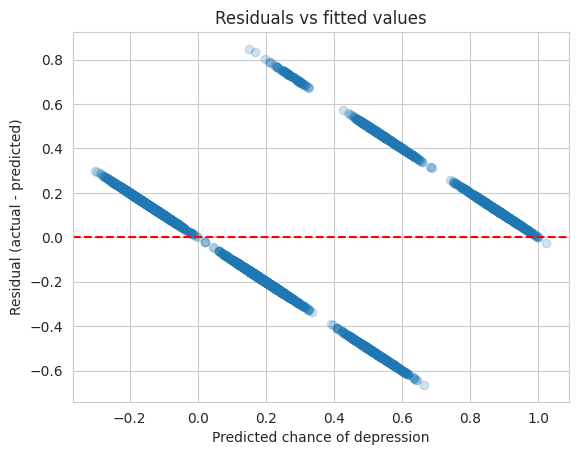

Average residual: -0.0


In [94]:
residuals = m_multi.resid
fitted = m_multi.fittedvalues

plt.scatter(fitted, residuals, alpha=0.2)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs fitted values")
plt.xlabel("Predicted chance of depression")
plt.ylabel("Residual (actual - predicted)")
plt.show()

print("Average residual:", round(residuals.mean(), 4))

# One prediction example for a manager

In [95]:
new_student = pd.DataFrame({
    "Health_Score": [2],            # Abnormal health
    "Friend_Flag": [0],             # no friend circle
    "CGPA": [3.2],
    "Bachelor_Flag": [1],           # lives away from family
    "Cost_without_study": [12000]
})

chance = m_multi.predict(new_student)[0]
print("Predicted chance of depression:", round(chance * 100, 1), "%")

Predicted chance of depression: 60.5 %


# Lecture 14 - Principal component analysis

In [96]:
# Step 1 - Group the variables
groups = {
    "Academic Stage": [
        "Age",
        "Current_semester"
    ],
    "Wellbeing": [
        "Health_Score",
        "Friend_Flag",
        "CGPA"
    ],
    "Living Situation": [
        "Cost_without_study",
        "Bachelor_Flag"
    ]
}

for name, cols in groups.items():
    c = df[cols].corr().values
    average = (c.sum() - len(cols)) / (len(cols) * (len(cols) - 1))   # average correlation inside the group
    print(f"{name}: {len(cols)} variables, average correlation {average:.2f}")

Academic Stage: 2 variables, average correlation 0.33
Wellbeing: 3 variables, average correlation 0.05
Living Situation: 2 variables, average correlation 0.11


# Step 2 - PCA on all 7 student variables

In [97]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca_cols = ["Age", "Current_semester", "CGPA", "Cost_without_study", "Health_Score", "Friend_Flag", "Bachelor_Flag"]

# Step A: Put every variable on the same scale
scaled = StandardScaler().fit_transform(df[pca_cols])

# Step B: Run PCA
pca = PCA()
scores = pca.fit_transform(scaled)

# Step C: How much does each component explain?
names = [f"PC{i+1}" for i in range(len(pca_cols))]

variance = pd.DataFrame({
    "Variance explained": pca.explained_variance_ratio_,
    "Cumulative": pca.explained_variance_ratio_.cumsum()
}, index=names)

variance.round(3)

,Variance explained,Cumulative
PC1,0.208,0.208
PC2,0.164,0.372
PC3,0.159,0.531
PC4,0.137,0.669
PC5,0.123,0.792
PC6,0.117,0.908
PC7,0.092,1.000


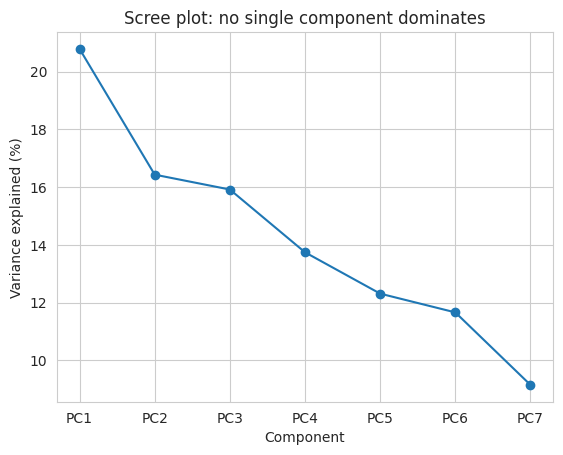

In [98]:
# Scree plot - how many components to keep?
plt.plot(names, pca.explained_variance_ratio_ * 100, marker="o")
plt.title("Scree plot: no single component dominates")
plt.xlabel("Component")
plt.ylabel("Variance explained (%)")
plt.show()

In [99]:
# Step D: The loadings show how much each variable counts in PC1, PC2 and PC3
loadings = pd.DataFrame(pca.components_[:3].T, index=pca_cols, columns=["PC1", "PC2", "PC3"])
loadings.round(2)

,PC1,PC2,PC3
Age,0.63,0.17,0.19
Current_semester,0.53,0.26,0.42
CGPA,-0.24,0.05,0.58
Cost_without_study,-0.24,0.64,0.19
Health_Score,0.11,-0.57,0.24
Friend_Flag,-0.05,-0.41,0.47
Bachelor_Flag,-0.44,0.09,0.37


# Step 3 - Can Age and Semester become one 'Academic Stage' index?

In [100]:
cols = groups["Academic Stage"]

scaled = StandardScaler().fit_transform(df[cols])
pca_stage = PCA()
stage_scores = pca_stage.fit_transform(scaled)

print(pd.Series(pca_stage.explained_variance_ratio_, index=["PC1", "PC2"]).round(2))

sign = 1 if pca_stage.components_[0].sum() > 0 else -1
print(pd.Series(pca_stage.components_[0] * sign, index=cols).round(2))

PC1    0.67
PC2    0.33
dtype: float64
Age                 0.71
Current_semester    0.71
dtype: float64


In [101]:
raw_index = stage_scores[:, 0] * sign

df["Stage_Index"] = (raw_index - raw_index.min()) / (raw_index.max() - raw_index.min()) * 100

# Does depression change with the academic stage index?
df["Stage_Band"] = pd.cut(df["Stage_Index"], bins=[0, 25, 50, 75, 100], include_lowest=True,
                          labels=["Early", "Middle", "Senior", "Final"])

(df.groupby("Stage_Band", observed=True)["Depression_Flag"].mean() * 100).round(1)

,Depression_Flag
Stage_Band,
Early,34.9
Middle,25.0
Senior,27.5
Final,22.8


# Extra numbers used in the report (for the verification log)

In [102]:
# 1. Students with Abnormal or Critical health, and how many of them are depressed
at_risk = df[df["Health_Score"] <= 2]
print("Abnormal + Critical students:", len(at_risk))
print("Depressed among them        :", at_risk["Depression_Flag"].sum(), "of", df["Depression_Flag"].sum())

# 2. Single students with no friend circle
lonely = df[(df["Relationship_status"] == "Single") & (df["friend_circle"] == "No")]
print("\nSingle + no friend circle:", len(lonely), "students |", round(lonely["Depression_Flag"].mean() * 100, 1), "% depressed")

# 3. Living style x friend circle (depression rate)
print(pd.crosstab(df["Living_style"], df["friend_circle"], values=df["Depression_Flag"], aggfunc="mean").round(3))

# 4. Low CGPA students
low = df[df["CGPA"] < 3]
print("\nCGPA below 3.0:", len(low), "students |", round(low["Depression_Flag"].mean() * 100, 1), "% depressed")
print(df.groupby("Depression")["CGPA"].mean().round(2))

# 5. Median living cost by family background
print(df.groupby("Family_background")["Cost_without_study"].median())

Abnormal + Critical students: 1515
Depressed among them        : 1118 of 1201

Single + no friend circle: 774 students | 44.1 % depressed
friend_circle     No    Yes
Living_style               
Bachelor       0.328  0.268
Family         0.356  0.203

CGPA below 3.0: 587 students | 39.2 % depressed
Depression
No     3.44
Yes    3.35
Name: CGPA, dtype: float64
Family_background
Lower Middle class     6100.0
Middle class          11304.5
Rich class            22702.0
Name: Cost_without_study, dtype: float64


In [103]:
# 6. Depression rate and number of students in each semester
sem_table = df.groupby("Current_semester")["Depression_Flag"].agg(["mean", "count"])
sem_table["mean"] = (sem_table["mean"] * 100).round(1)
sem_table

,mean,count
Current_semester,,
1,34.1,88
2,30.8,543
3,27.4,511
4,23.3,553
5,26.6,794
6,26.6,500
7,25.2,404
8,27.2,511
9,31.1,286


In [104]:
# 7. Numbers behind the quiver plot: depression rate (%) by division, Family vs Bachelor
quiver_table = pd.DataFrame({
    "Family": family["Depression_Flag"] * 100,
    "Bachelor": bachelor["Depression_Flag"] * 100
})
quiver_table["Change"] = quiver_table["Bachelor"] - quiver_table["Family"]
quiver_table.round(2)

,Family,Bachelor,Change
Home_division,,,
Barisal,30.50,25.70,-4.80
Chittagong,30.99,30.13,-0.86
Dhaka,21.19,24.09,2.91
Khulna,23.61,35.84,12.23
Mymensingh,34.03,23.20,-10.83
Rajshahi,29.10,32.49,3.38
Rangpur,30.34,33.03,2.68
Sylhet,22.67,24.18,1.50
